<a href="https://colab.research.google.com/github/danilejt/DataAnalytics-2026/blob/main/W5D1MINIPROJECTAPPLE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Data Loading and Exploration
2. Data Visualization
3. Statistical Analysis
4. Hypothesis Testing
5. Advanced Statistical Techniques (Bonus)
    - Signal Processing using SciPy
    - Statistical Functions in NumPy
6. Summary and Insights
7. *Reflection*

1. Data Loading and Exploration


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Load fresh from CSV with DD/MM/YYYY format
asp = pd.read_csv('/content/Apple Stock Prices (1981 to 2023).csv')
asp.info()
asp['Date'] = pd.to_datetime(asp['Date'], format='%d/%m/%Y')
asp = asp.set_index('Date').sort_index()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10608 entries, 0 to 10607
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       10608 non-null  object 
 1   Open       10608 non-null  float64
 2   High       10608 non-null  float64
 3   Low        10608 non-null  float64
 4   Close      10608 non-null  float64
 5   Adj Close  10608 non-null  float64
 6   Volume     10608 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 580.3+ KB


In [6]:
print("\n--- Null Values Count ---")
print(asp.isnull().sum())
#checked for null values and none were found!

# Get basic summary statistics for numerical columns
print("\n--- Summary Statistics ---")
display(asp.describe())


--- Null Values Count ---
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

--- Summary Statistics ---


,Open,High,Low,Close,Adj Close,Volume
count,10608.000000,10608.000000,10608.000000,10608.000000,10608.000000,1.060800e+04
mean,16.689173,16.879955,16.500822,16.697362,16.027345,3.275098e+08
std,35.450519,35.882848,35.031289,35.473912,35.154878,3.378203e+08
min,0.049665,0.049665,0.049107,0.049107,0.038213,0.000000e+00
25%,0.287946,0.296875,0.282355,0.288923,0.238909,1.213044e+08
50%,0.488839,0.495536,0.480446,0.487701,0.404851,2.145976e+08
75%,16.320893,16.418483,16.151249,16.269554,14.073167,4.066804e+08
max,182.630005,182.940002,179.119995,182.009995,180.959747,7.421641e+09


In [7]:
# Verify the column is now a datetime64[ns] object
print(asp.dtypes)
print("Columns:", asp.columns.tolist())
print("Index:", asp.index[:2])

Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object
Columns: ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
Index: DatetimeIndex(['1981-01-02', '1981-01-05'], dtype='datetime64[ns]', name='Date', freq=None)


In [8]:
print(f"\nDate Range: {asp.index.min()} to {asp.index.max()}")
print(f"\nTotal Trading Days: {len(asp)}")


Date Range: 1981-01-02 00:00:00 to 2023-01-27 00:00:00

Total Trading Days: 10608


2. Data Visualization

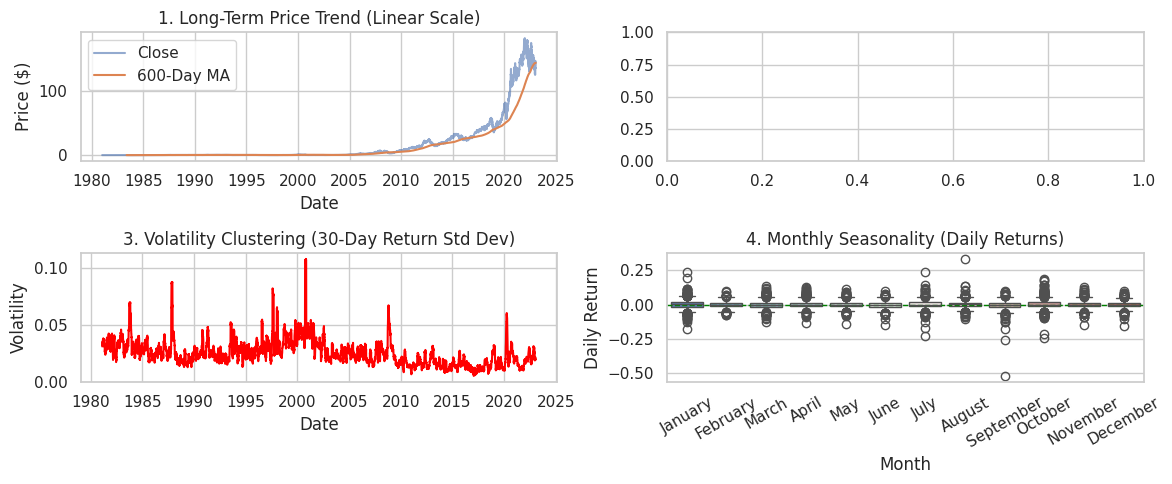

In [9]:
sns.set_theme(style="whitegrid")

# 2. Compute Trend, Volatility & Calendar Features
asp["SMA_600"] = asp["Close"].rolling(window=600).mean()
asp["Daily_Return"] = asp["Close"].pct_change()
asp["Volatility_30d"] = asp["Daily_Return"].rolling(window=30).std()
asp["Month"] = asp.index.month_name()

# 3. Visualize Time Series Properties (2x2 Grid)
fig, axes = plt.subplots(2, 2, figsize=(12, 5))

# Panel 1: Linear Price Trend + Moving Averages
sns.lineplot(data=asp, x=asp.index, y="Close", ax=axes[0, 0], label="Close", alpha=0.6)
sns.lineplot(data=asp, x=asp.index, y="SMA_600", ax=axes[0, 0], label="600-Day MA")
axes[0, 0].set_title("1. Long-Term Price Trend (Linear Scale)")
axes[0, 0].set_ylabel("Price ($)")

# Panel 2: 30-Day Rolling Volatility (Volatility Clustering)
sns.lineplot(data=asp, x=asp.index, y="Volatility_30d", ax=axes[1, 0], color="red")
axes[1, 0].set_title("3. Volatility Clustering (30-Day Return Std Dev)")
axes[1, 0].set_ylabel("Volatility")

# Panel 3: Monthly Seasonality of Daily Returns
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
sns.boxplot(data=asp, x="Month", y="Daily_Return", order=month_order,
            ax=axes[1, 1], hue="Month", palette="vlag", legend=False)
axes[1, 1].axhline(0, color="green", linestyle="--", linewidth=1)
axes[1, 1].set_title("4. Monthly Seasonality (Daily Returns)")
axes[1, 1].set_ylabel("Daily Return")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


Utilize Matplotlib to plot closing prices and traded volume over time.
Create a candlestick chart to depict high and low prices.

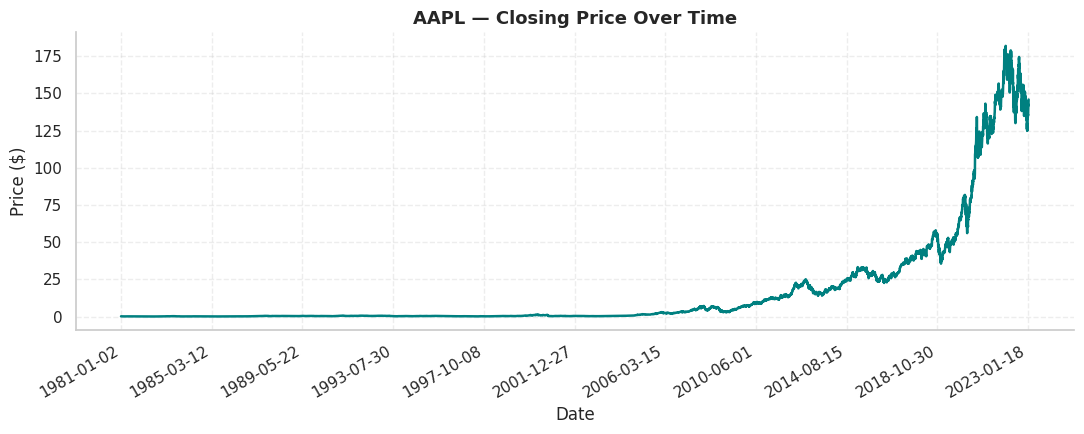

In [12]:
import matplotlib.pyplot as plt
import numpy as np

dates = asp.index.astype(str).to_numpy()
x = np.arange(len(dates))
close_p = asp["Close"].to_numpy()

fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(x, close_p, color="teal", linewidth=1.8, label="Close Price")

ax.set_title("AAPL — Closing Price Over Time", fontsize=13, fontweight="bold")
ax.set_ylabel("Price ($)")
ax.set_xlabel("Date")

step = max(1, len(dates) // 10)
ax.set_xticks(x[::step])
ax.set_xticklabels(dates[::step], rotation=30, ha="right")

ax.grid(True, linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


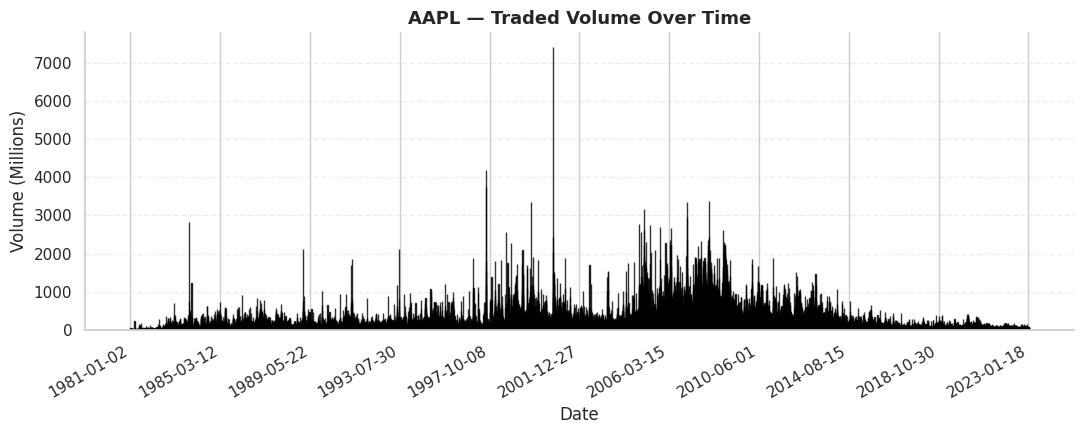

In [16]:
volume = asp["Volume"].to_numpy()

fig, ax = plt.subplots(figsize=(11, 4.5))

ax.bar(x, volume / 1e6, width=1.2, color="black", edgecolor="black", alpha=0.8)

ax.set_title("AAPL — Traded Volume Over Time", fontsize=13, fontweight="bold")
ax.set_ylabel("Volume (Millions)")
ax.set_xlabel("Date")

step = max(1, len(dates) // 10)
ax.set_xticks(x[::step])
ax.set_xticklabels(dates[::step], rotation=30, ha="right")

ax.grid(True, axis="y", linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

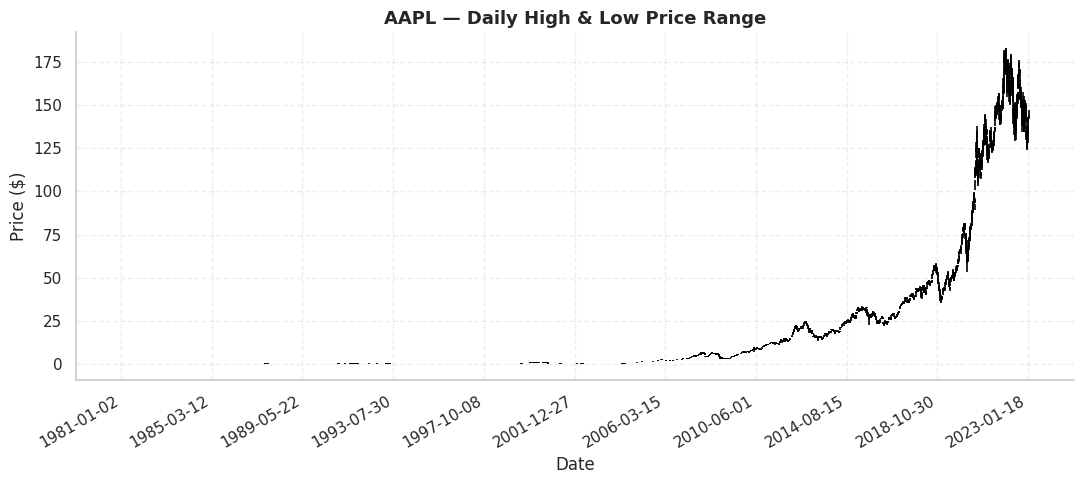

In [17]:
high_p = asp["High"].to_numpy()
low_p = asp["Low"].to_numpy()

fig, ax = plt.subplots(figsize=(11, 5))

ax.vlines(x, low_p, high_p, color="black", linewidth=1.2)

ax.set_title("AAPL — Daily High & Low Price Range", fontsize=13, fontweight="bold")
ax.set_ylabel("Price ($)")
ax.set_xlabel("Date")

step = max(1, len(dates) // 10)
ax.set_xticks(x[::step])
ax.set_xticklabels(dates[::step], rotation=30, ha="right")

ax.grid(True, linestyle="--", alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

3. Statistical Analysis
Statistical Analysis
Compute summary statistics (mean, median, standard deviation) for key columns.
Analyze closing prices with a moving average.

In [23]:
columns = ["Open", "High", "Low", "Close", "Volume"]

for column in columns:
  array = asp[column].to_numpy()
  print(f"{column}:")
  print(f"  Mean:   {np.mean(array):,.2f}")
  print(f"  Median: {np.median(array):,.2f}")
  print(f"  Std:    {np.std(array, ddof=1):,.2f}\n")


Open:
  Mean:   16.69
  Median: 0.49
  Std:    35.45

High:
  Mean:   16.88
  Median: 0.50
  Std:    35.88

Low:
  Mean:   16.50
  Median: 0.48
  Std:    35.03

Close:
  Mean:   16.70
  Median: 0.49
  Std:    35.47

Volume:
  Mean:   327,509,817.26
  Median: 214,597,600.00
  Std:    337,820,279.06



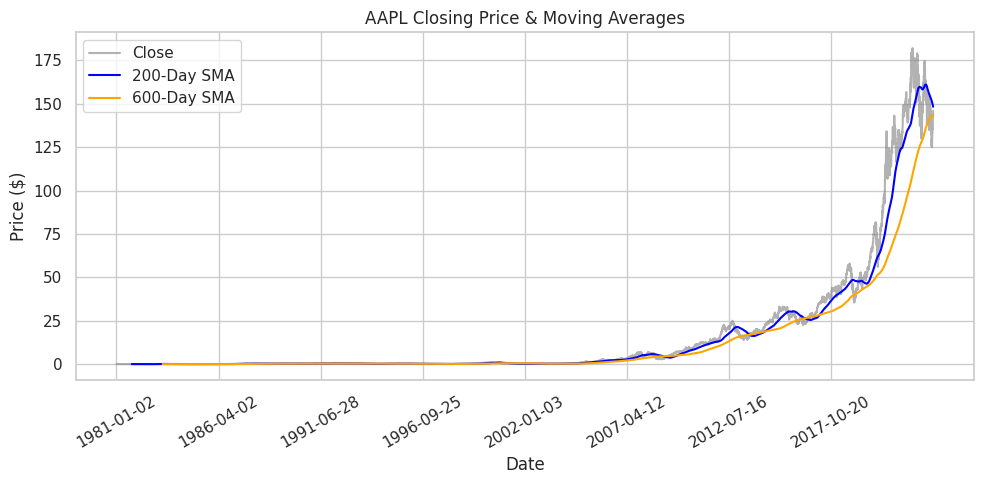

In [26]:
# Moving averages
# sma_200 = np.convolve(close_p, np.ones(200) / 200, mode="valid")
# sma_600 = np.convolve(close_p, np.ones(600) / 600, mode="valid")
asp["sma_200"] = asp["Close"].rolling(window=200).mean()
asp["sma_600"] = asp["Close"].rolling(window=600).mean()

# Plot
plt.figure(figsize=(10, 5))
plt.plot(x, close_p, color="gray", alpha=0.6, label="Close")
plt.plot(x[199:], sma_200, color="blue", label="200-Day SMA")
plt.plot(x[599:], sma_600, color="orange", label="600-Day SMA")

plt.title("AAPL Closing Price & Moving Averages")
plt.ylabel("Price ($)")
plt.xlabel("Date")
plt.xticks(x[:: len(x) // 8], dates[:: len(x) // 8], rotation=30)
plt.legend()
plt.tight_layout()
plt.show()


Hypothesis Testing:
Execute a t-test to compare average closing prices across different years.
Examine daily returns’ distribution and test for normality using SciPy.

In [27]:
import pandas as pd
from scipy import stats

asp.index = pd.to_datetime(asp.index)

# 2. Pick two years to compare (check available years with asp.index.year.unique())
year1, year2 = 2022, 2023

close_y1 = asp[asp.index.year == year1]["Close"].dropna()
close_y2 = asp[asp.index.year == year2]["Close"].dropna()

# 3. Execute Welch's two-sample t-test
t_stat, p_value = stats.ttest_ind(close_y1, close_y2, equal_var=False)

# 4. Print results
print(f"{year1} Mean Close: ${close_y1.mean():.2f} (n={len(close_y1)})")
print(f"{year2} Mean Close: ${close_y2.mean():.2f} (n={len(close_y2)})")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value:     {p_value:.4e}")

if p_value < 0.05:
  print(
      f"Result: Statistically significant difference between {year1} and"
      f" {year2} (p < 0.05)."
  )
else:
  print(
      f"Result: No statistically significant difference between {year1} and"
      f" {year2} (p >= 0.05)."
  )


2022 Mean Close: $154.84 (n=251)
2023 Mean Close: $134.90 (n=18)
T-statistic: 11.5816
P-value:     2.7618e-12
Result: Statistically significant difference between 2022 and 2023 (p < 0.05).


In [30]:
import pandas as pd
from scipy import stats

asp.index = pd.to_datetime(asp.index)
years = sorted(asp.index.year.unique())

results = []
for i in range(len(years) - 1):
  y1, y2 = years[i], years[i + 1]

  close_y1 = asp[asp.index.year == y1]["Close"].dropna()
  close_y2 = asp[asp.index.year == y2]["Close"].dropna()

  t_stat, p_val = stats.ttest_ind(close_y1, close_y2, equal_var=False)

  results.append({
      "Years": f"{y1} vs {y2}",
      "Mean Y1 ($)": round(close_y1.mean(), 1),
      "Mean Y2 ($)": round(close_y2.mean(), 1),
      "Change ($)": round(close_y2.mean() - close_y1.mean(), 1),
      "T-Stat": round(t_stat, 2),
      "P-Value": f"{p_val:.4e}",
      "Significant (p<0.05)": p_val < 0.05,
  })

# 3. Display results as a clean table
comparison_df = pd.DataFrame(results)
print(comparison_df.to_string(index=False))


       Years  Mean Y1 ($)  Mean Y2 ($)  Change ($)  T-Stat     P-Value  Significant (p<0.05)
1981 vs 1982          0.1          0.1        -0.0   10.58  1.1531e-23                  True
1982 vs 1983          0.1          0.2         0.1  -21.35  2.0823e-66                  True
1983 vs 1984          0.2          0.1        -0.0   13.65  1.4382e-32                  True
1984 vs 1985          0.1          0.1        -0.0   20.85  6.4325e-64                  True
1985 vs 1986          0.1          0.1         0.1  -27.23  1.0270e-99                  True
1986 vs 1987          0.1          0.3         0.2  -40.46 1.2193e-124                  True
1987 vs 1988          0.3          0.4         0.0   -4.66  4.8634e-06                  True
1988 vs 1989          0.4          0.4         0.0   -0.39  6.9563e-01                 False
1989 vs 1990          0.4          0.3        -0.0   10.44  3.1767e-23                  True
1990 vs 1991          0.3          0.5         0.1  -28.00  2.7849e-99

Mean:     0.11%
Std Dev:  2.82%
Skewness: -0.38
Kurtosis: 18.13


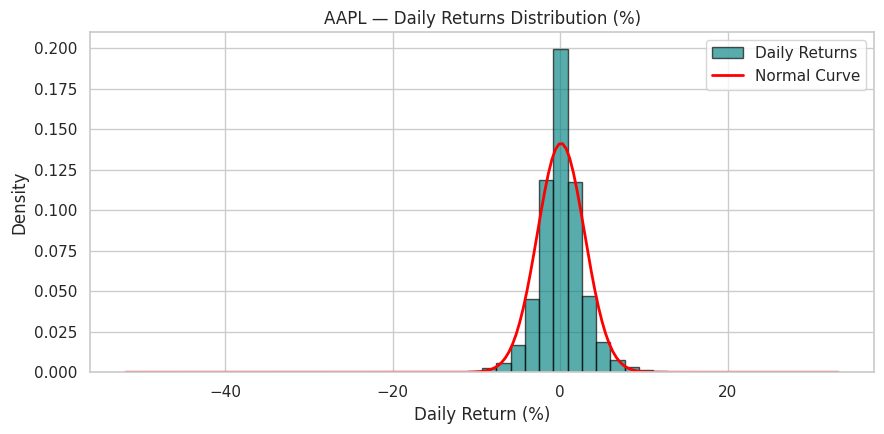

In [31]:
from scipy.stats import norm

# 1. Daily returns (%)
returns = asp["Close"].pct_change().dropna() * 100

# 2. Quick stats
print(f"Mean:     {returns.mean():.2f}%")
print(f"Std Dev:  {returns.std():.2f}%")
print(f"Skewness: {returns.skew():.2f}")
print(f"Kurtosis: {returns.kurt():.2f}")

# 3. Histogram + Normal curve
plt.figure(figsize=(9, 4.5))
plt.hist(
    returns,
    bins=50,
    density=True,
    color="teal",
    alpha=0.65,
    edgecolor="black",
    label="Daily Returns",
)

x = np.linspace(returns.min(), returns.max(), 200)
plt.plot(
    x,
    norm.pdf(x, returns.mean(), returns.std()),
    color="red",
    linewidth=2,
    label="Normal Curve",
)

plt.title("AAPL — Daily Returns Distribution (%)")
plt.xlabel("Daily Return (%)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()


In [33]:
k2_stat, k2_p_value = stats.normaltest(returns)
print(f"D'Agostino K^2: stat={k2_stat:.2f}, p-value={k2_p_value:.4e}")


print(f"D'Agostino K^2 Statistic: {k2_stat:.2f}")
print(f"P-Value: {k2_p_value:.4e}")
print(
    "Normal distribution?"
    f" {'Yes (p >= 0.05)' if p_value >= 0.05 else 'No (p < 0.05)'}"
)


D'Agostino K^2: stat=2719.21, p-value=0.0000e+00
D'Agostino K^2 Statistic: 2719.21
P-Value: 0.0000e+00
Normal distribution? No (p < 0.05)



Bonus: np.corrcoef

=== Correlation Matrix ===
                       Open         High          Low        Close       Volume Daily Return
Open                  1.000        1.000        1.000        1.000       -0.215       -0.001
High                  1.000        1.000        1.000        1.000       -0.214        0.000
Low                   1.000        1.000        1.000        1.000       -0.216        0.001
Close                 1.000        1.000        1.000        1.000       -0.215        0.003
Volume               -0.215       -0.214       -0.216       -0.215        1.000        0.001
Daily Return         -0.001        0.000        0.001        0.003        0.001        1.000


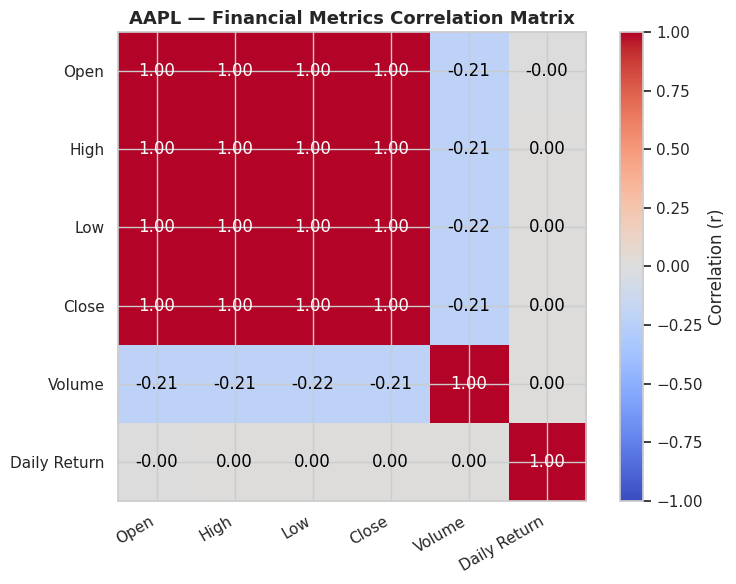

In [34]:
df_clean = asp[["Open", "High", "Low", "Close", "Volume"]].copy()
df_clean["Daily_Return"] = df_clean["Close"].pct_change()
df_clean = df_clean.dropna()

labels = ["Open", "High", "Low", "Close", "Volume", "Daily Return"]
data = df_clean.to_numpy().T  # Transpose so each row is a variable

# 2. Compute correlation matrix using NumPy
corr_matrix = np.corrcoef(data)

# 3. Print formatted correlation matrix
print("=== Correlation Matrix ===")
header = " " * 14 + "".join(f"{name:>13}" for name in labels)
print(header)
for name, row in zip(labels, corr_matrix):
  print(f"{name:<14}" + "".join(f"{val:>13.3f}" for val in row))

# 4. Plot Correlation Heatmap in Matplotlib
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

# Add tick labels & values inside each cell
ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_yticklabels(labels)

for i in range(len(labels)):
  for j in range(len(labels)):
    val = corr_matrix[i, j]
    text_color = "white" if abs(val) > 0.6 else "black"
    ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=text_color)

plt.colorbar(im, ax=ax, label="Correlation (r)")
ax.set_title(
    "AAPL — Financial Metrics Correlation Matrix", fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.show()
